<a href="https://colab.research.google.com/github/ancestor9/Scikit-learn-model-selection-evaluation/blob/main/seminar_note_load_dataset.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Dataset

In [ ]:
from IPython.core.interactiveshell import InteractiveShell # 모든 명령어 출력
InteractiveShell.ast_node_interactivity = 'all'
from IPython.core.display import display, HTML # 화면 좌우 크기 100%
display(HTML("<style>.container { width:100% !important; }</style>"))
import warnings # 파이썬 버전에 따른 오류 출력 방지
warnings.filterwarnings('ignore')

import matplotlib.pyplot as plt # 시각화 matplob
import seaborn as sns; sns.set() # 시각화 seaborn

## 1. Toy dataset

In [ ]:
import sklearn.datasets as datasets

# load_로 시작하는 toy dataset 불러오기 함수 목록 확인
toy_dataset_loaders = [name for name in dir(datasets) if name.startswith('load_')]
print(toy_dataset_loaders)

['load_breast_cancer', 'load_diabetes', 'load_digits', 'load_files', 'load_iris', 'load_linnerud', 'load_sample_image', 'load_sample_images', 'load_svmlight_file', 'load_svmlight_files', 'load_wine']


In [ ]:
from sklearn.datasets import load_breast_cancer
data = load_breast_cancer()
data

{'data': array([[1.799e+01, 1.038e+01, 1.228e+02, ..., 2.654e-01, 4.601e-01,
         1.189e-01],
        [2.057e+01, 1.777e+01, 1.329e+02, ..., 1.860e-01, 2.750e-01,
         8.902e-02],
        [1.969e+01, 2.125e+01, 1.300e+02, ..., 2.430e-01, 3.613e-01,
         8.758e-02],
        ...,
        [1.660e+01, 2.808e+01, 1.083e+02, ..., 1.418e-01, 2.218e-01,
         7.820e-02],
        [2.060e+01, 2.933e+01, 1.401e+02, ..., 2.650e-01, 4.087e-01,
         1.240e-01],
        [7.760e+00, 2.454e+01, 4.792e+01, ..., 0.000e+00, 2.871e-01,
         7.039e-02]], shape=(569, 30)),
 'target': array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1,
        0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0,
        0, 0, 1, 0, 1, 1, 1, 1, 1, 0, 0, 1, 0, 0, 1, 1, 1, 1, 0, 1, 0, 0,
        1, 1, 1, 1, 0, 1, 0, 0, 1, 0, 1, 0, 0, 1, 1, 1, 0, 0, 1, 0, 0, 0,
        1, 1, 1, 0, 1, 1, 0, 0, 1, 1, 1, 0, 0, 1, 1, 1, 1, 0, 1, 1, 0, 1,
        1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 1,

In [ ]:
data.data[0:1]
data.target[0:10]
print(data.DESCR)

array([[1.799e+01, 1.038e+01, 1.228e+02, 1.001e+03, 1.184e-01, 2.776e-01,
        3.001e-01, 1.471e-01, 2.419e-01, 7.871e-02, 1.095e+00, 9.053e-01,
        8.589e+00, 1.534e+02, 6.399e-03, 4.904e-02, 5.373e-02, 1.587e-02,
        3.003e-02, 6.193e-03, 2.538e+01, 1.733e+01, 1.846e+02, 2.019e+03,
        1.622e-01, 6.656e-01, 7.119e-01, 2.654e-01, 4.601e-01, 1.189e-01]])

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0])

.. _breast_cancer_dataset:

Breast cancer wisconsin (diagnostic) dataset
--------------------------------------------

**Data Set Characteristics:**

:Number of Instances: 569

:Number of Attributes: 30 numeric, predictive attributes and the class

:Attribute Information:
    - radius (mean of distances from center to points on the perimeter)
    - texture (standard deviation of gray-scale values)
    - perimeter
    - area
    - smoothness (local variation in radius lengths)
    - compactness (perimeter^2 / area - 1.0)
    - concavity (severity of concave portions of the contour)
    - concave points (number of concave portions of the contour)
    - symmetry
    - fractal dimension ("coastline approximation" - 1)

    The mean, standard error, and "worst" or largest (mean of the three
    worst/largest values) of these features were computed for each image,
    resulting in 30 features.  For instance, field 0 is Mean Radius, field
    10 is Radius SE, field 20 is Worst Radius.

    - 

In [ ]:
import pandas as pd
import numpy as np

df= pd.DataFrame(housing.data, columns=housing.feature_names)
df['target']= housing.target
df.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,target
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


## 데이터 현황파악 script

In [ ]:
pd.DataFrame({'자료 내용(contents)':{col:df[col].unique() for col in df},
              '데이터형태(dtypes)':{col:df[col].dtype for col in df},
              '고유값 수(nunique)':{col:len(df[col].unique()) for col in df},
              '결측치 비율(%)':{col:str(round(sum(df[col].isna())/len(df),2))+'%' for col in df},
              '중복건수':{col:sum(df[col].duplicated()) for col in df},
              'nan 비율':{col:int(df[df[col] == 'nan'].shape[0]/len(df)*100) for col in df}
             })

,자료 내용(contents),데이터형태(dtypes),고유값 수(nunique),결측치 비율(%),중복건수,nan 비율
MedInc,"[8.3252, 8.3014, 7.2574, 5.6431, 3.8462, 4.036...",float64,12928,0.0%,7712,0
HouseAge,"[41.0, 21.0, 52.0, 42.0, 50.0, 40.0, 49.0, 48....",float64,52,0.0%,20588,0
AveRooms,"[6.984126984126984, 6.238137082601054, 8.28813...",float64,19392,0.0%,1248,0
AveBedrms,"[1.0238095238095237, 0.9718804920913884, 1.073...",float64,14233,0.0%,6407,0
Population,"[322.0, 2401.0, 496.0, 558.0, 565.0, 413.0, 10...",float64,3888,0.0%,16752,0
AveOccup,"[2.5555555555555554, 2.109841827768014, 2.8022...",float64,18841,0.0%,1799,0
Latitude,"[37.88, 37.86, 37.85, 37.84, 37.83, 37.82, 37....",float64,862,0.0%,19778,0
Longitude,"[-122.23, -122.22, -122.24, -122.25, -122.26, ...",float64,844,0.0%,19796,0
target,"[4.526, 3.585, 3.521, 3.413, 3.422, 2.697, 2.9...",float64,3842,0.0%,16798,0


## 2.	Real world datasets

In [ ]:
from sklearn.datasets import fetch_20newsgroups
newsgroups= fetch_20newsgroups()
newsgroups.keys()

df= pd.DataFrame(newsgroups.data, columns=['contents'])
df['target']= newsgroups.target
df.head()

dict_keys(['data', 'filenames', 'target_names', 'target', 'DESCR'])

,contents,target
0,From: lerxst@wam.umd.edu (where's my thing)\nS...,7
1,From: guykuo@carson.u.washington.edu (Guy Kuo)...,4
2,From: twillis@ec.ecn.purdue.edu (Thomas E Will...,4
3,From: jgreen@amber (Joe Green)\nSubject: Re: W...,1
4,From: jcm@head-cfa.harvard.edu (Jonathan McDow...,14


In [ ]:
newsgroups_train = fetch_20newsgroups(subset='train')
newsgroups_train.keys()
newsgroups_train.target.shape
newsgroups_test = fetch_20newsgroups(subset='test')
newsgroups_test.target.shape

dict_keys(['data', 'filenames', 'target_names', 'target', 'DESCR'])

(11314,)

(7532,)

## 3. Open ML datasets

In [ ]:
from sklearn.datasets import fetch_openml
data = fetch_openml(name='wine-quality-white')
data.url
data.keys()
df = pd.DataFrame(np.c_[data.data, data.target], columns= data.feature_names + ['target'])
df.head()

'https://www.openml.org/d/40498'

dict_keys(['data', 'target', 'frame', 'categories', 'feature_names', 'target_names', 'DESCR', 'details', 'url'])

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,target
0,7.0,0.27,0.36,20.7,0.045,45.0,170.0,1.001,3.0,0.45,8.8,4
1,6.3,0.3,0.34,1.6,0.049,14.0,132.0,0.994,3.3,0.49,9.5,4
2,8.1,0.28,0.4,6.9,0.05,30.0,97.0,0.9951,3.26,0.44,10.1,4
3,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.4,9.9,4
4,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.4,9.9,4


## 3.	Generated datasets

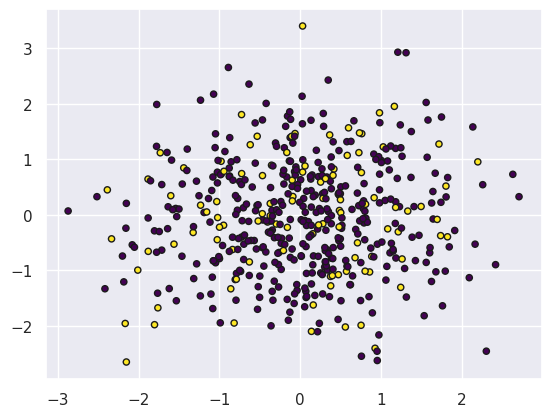

In [ ]:
from sklearn.datasets import make_classification
X, y = make_classification(n_samples=500, n_classes=2, weights=[0.8, 0.2],
                          random_state=1)
plt.scatter(X[:, 0], X[:, 1], c=y, s=20, cmap='viridis', edgecolor='k')

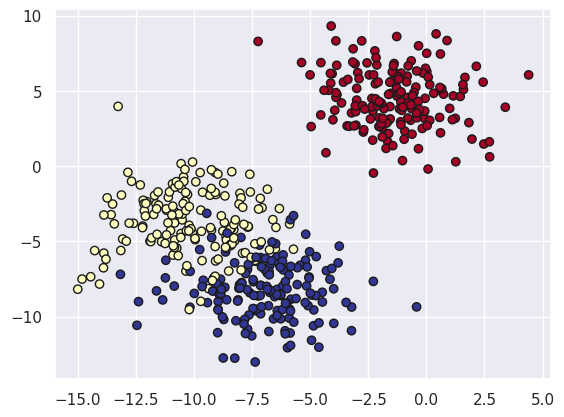

In [ ]:
from sklearn.datasets import make_moons, make_circles, make_blobs
X, y = make_blobs(n_samples=500, centers=3,
                  n_features=2, cluster_std=2, random_state=1)
plt.scatter(X[:, 0], X[:, 1], c=y, cmap='RdYlBu', edgecolor='k')

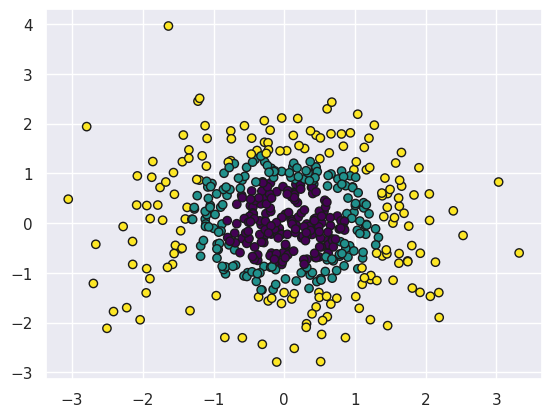

In [ ]:
from sklearn.datasets import make_gaussian_quantiles
X, y = make_gaussian_quantiles(n_samples=500, n_features=2, n_classes=3, random_state=1)
plt.scatter(X[:, 0], X[:, 1], c=y, cmap='viridis', edgecolor='k')

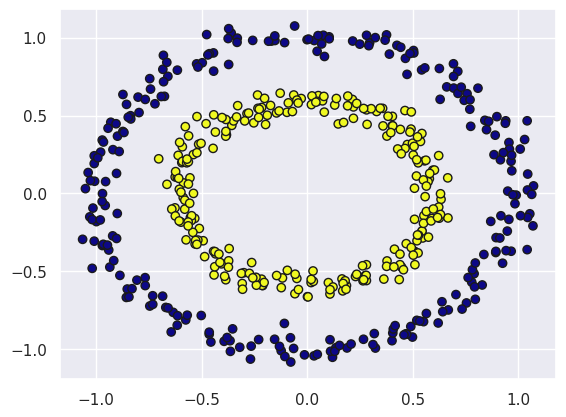

In [ ]:
X, y = make_circles(n_samples=500, factor=.6, noise=.05)
plt.scatter(X[:, 0], X[:, 1], c=y, cmap='plasma', edgecolor='k')

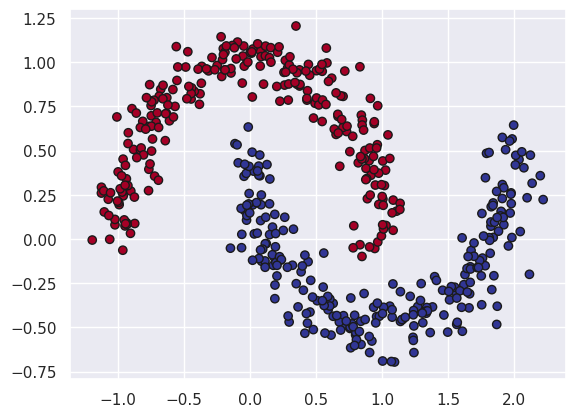

In [ ]:
X, y = make_moons(n_samples=500, noise=.1)
plt.scatter(X[:, 0], X[:, 1], c=y, cmap='RdYlBu', edgecolor='k')

In [ ]:
df = pd.DataFrame(dict(x1=X[:,0], x2=X[:,1], target=y))
df.describe()

,x1,x2,target
count,500.000000,500.000000,500.000000
mean,0.499605,0.256413,0.500000
std,0.868871,0.506004,0.500501
min,-1.193172,-0.696070,0.000000
25%,-0.048448,-0.160571,0.000000
50%,0.503398,0.238397,0.500000
75%,1.071536,0.701405,1.000000
max,2.218319,1.204353,1.000000


## scikit learn overview

In [ ]:
from sklearn.datasets import load_wine
data = load_wine()
df = pd.DataFrame(np.c_[data.data, data.target], columns= data.feature_names + ['target'])
df= df[['flavanoids','color_intensity', 'target']]
df.head()

,flavanoids,color_intensity,target
0,3.06,5.64,0.0
1,2.76,4.38,0.0
2,3.24,5.68,0.0
3,3.49,7.80,0.0
4,2.69,4.32,0.0


<Axes: xlabel='flavanoids', ylabel='color_intensity'>

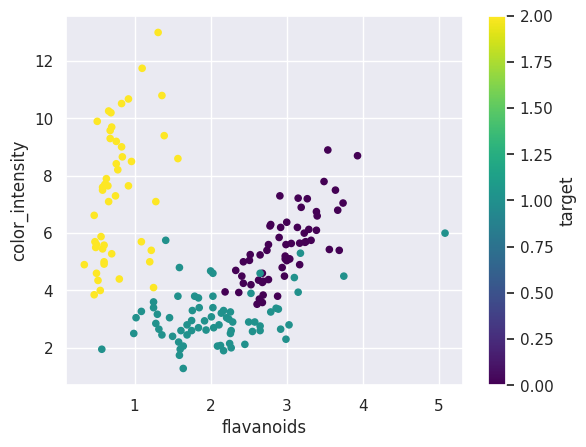

In [ ]:
df.plot.scatter('flavanoids','color_intensity',c='target', cmap='viridis')

In [ ]:
df.groupby('target').mean().round(2)

,flavanoids,color_intensity
target,,
0.0,2.98,5.53
1.0,2.08,3.09
2.0,0.78,7.40


In [ ]:
X = df.groupby('target').mean().values
y = df.target.unique()  # classes of each sample

In [ ]:
from sklearn.ensemble import RandomForestClassifier
clf = RandomForestClassifier(random_state=0)
clf.fit(X,y)
clf.predict([[3, 6]])

RandomForestClassifier(random_state=0)

array([0.])

In [ ]:
X= df.drop('target', axis=1)
y= df.target
y_pred = clf.predict(X)
(y_pred == y).mean()

np.float64(1.0)

In [ ]:
from sklearn.metrics import accuracy_score # 사이킷런의 정확도 산출 모듈
accuracy_score(y_pred, y)

1.0

In [ ]:
X= df.drop('target', axis=1)
y = df.target
clf = RandomForestClassifier(random_state=0)
clf.fit(X,y)

RandomForestClassifier(random_state=0)

In [ ]:
y_pred = clf.fit(X,y).predict(X)
accuracy_score(y_pred, y)

1.0

# Data, Algorithm, Model

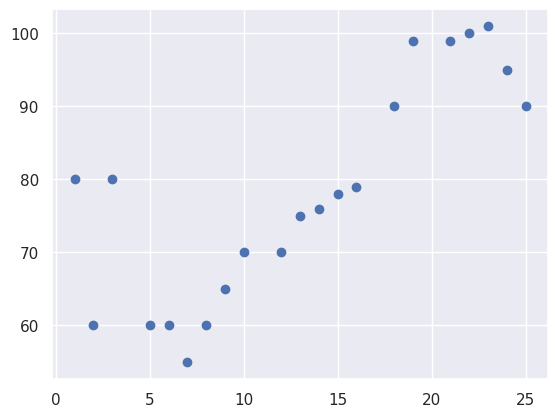

In [ ]:
x = [1,2,3,5,6,7,8,9,10,12,13,14,15,16,18,19,21,22,23,24,25]
y = [80,60,80,60,60,55,60,65,70,70,75,76,78,79,90,99,99,100,101,95,90]

plt.scatter(x, y)
plt.show()

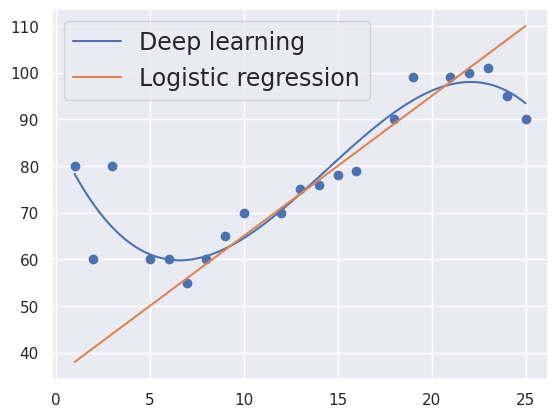

In [ ]:
myline = np.linspace(1, 25, 100)
polymodel = np.poly1d(np.polyfit(x, y, 3))
regy = 35 + myline*3
plt.scatter(x, y)
plt.plot(myline, polymodel(myline), label = 'Deep learning')
plt.plot(myline, regy, label = 'Logistic regression')
#plt.axhline(y = np.mean(y), label = '평균예측')
plt.legend(fontsize='17')
plt.show()

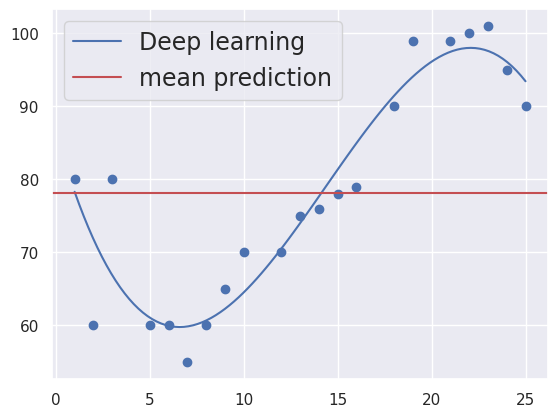

In [ ]:
plt.scatter(x, y)
plt.plot(myline, polymodel(myline), label = 'Deep learning')
plt.axhline(y = np.mean(y), label = 'mean prediction', color = 'r', linestyle = '-')
plt.legend(fontsize='17')
plt.show()

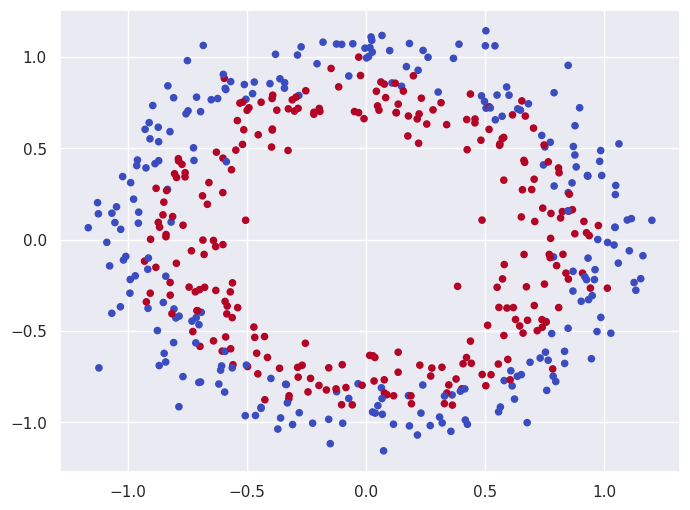

In [ ]:
plt.rcParams["figure.figsize"] = (8,6)
from sklearn.datasets import make_circles
X, y = make_circles(n_samples=500, random_state=11, noise=0.1)
plt.scatter(X[:, 0], X[:, 1], c=y, s=20, cmap='coolwarm');plt.show()

<Figure size 800x800 with 0 Axes>

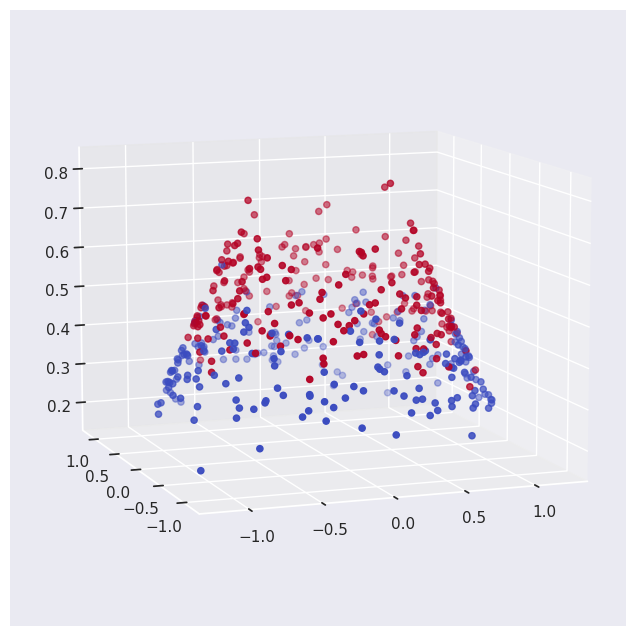

In [ ]:
from mpl_toolkits import mplot3d
r = np.exp(-(X ** 2).sum(1))
plt.figure(figsize=(8,8))
ax = plt.axes(projection='3d')
ax.scatter3D(X[:, 0], X[:, 1], r, c=y, cmap='coolwarm')
ax.view_init(10, 250)

# End